## 분류 모델과 로지스틱 회귀


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

SEED = 42


### 분류란 무엇인가

회귀와 분류는 모두 입력과 정답의 관계를 학습하고, 새로운 입력의 정답을 예측하는 지도학습이다. 회귀는 몸무게나 연비 같은 수치값을 예측하고, 분류는 악성·양성 종양이나 스팸·정상 메일처럼 정해진 범주를 예측한다. 분류에서 각각의 범주를 클래스라고 한다.

두 클래스 중 하나를 예측하면 이진 분류, 세 개 이상의 클래스 중 하나를 예측하면 다중 클래스 분류다.
이진 분류에서는 관심 대상으로 정한 클래스를 양성, 나머지를 음성이라고 한다.


### 로지스틱 회귀

로지스틱 회귀(Logistic Regression)는 특성의 가중합을 0~1 사이의 값으로 바꾸어 양성 클래스의 확률을 추정한다. 이렇게 얻은 확률을 임계값과 비교하면 입력이 어느 클래스에 속하는지 예측할 수 있다.


### 로지스틱 회귀와 시그모이드

입력 특성이 여러 개라면 각각에 가중치를 곱해 더하고, 여기에 절편을 더해 가중합을 구한다. 로지스틱 회귀는 이 가중합을 바탕으로 확률을 계산한다.

$$
z = x_1 w_1 + x_2 w_2 + \cdots + x_n w_n + b
$$

$n$은 입력 특성의 개수, $x_i$는 한 사례의 $i$번째 특성값, $w_i$는 그 특성의 반영 정도를 정하는 가중치, $b$는 입력과 무관하게 더하는 상수인 절편이다.


가중합 $z$는 음수나 1보다 큰 값이 될 수 있으므로, 확률로 표현하려면 값을 0과 1 사이로 바꾸어야 한다. 이 변환에 사용하는 시그모이드 함수는 다음과 같으며, 로지스틱 회귀는 변환한 값을 양성 클래스의 확률 $p$로 모델링한다.

$$
p = \frac{1}{1 + e^{-z}}
$$

식에서 $e$는 자연상수이며, 시그모이드의 그래프는 S자 모양을 띤다. 가운데인 $z=0$에서는 $p=0.5$가 되고, $z$가 커질수록 $p$는 1에, 작아질수록 0에 가까워진다.

확률을 클래스로 바꾸는 기준을 임계값이라고 한다. 예를 들어 임계값을 0.5로 정하면 $p > 0.5$일 때 클래스 1, $p \leq 0.5$일 때 클래스 0으로 분류한다. 이는 $z > 0$인지로 나누는 것과 같다.

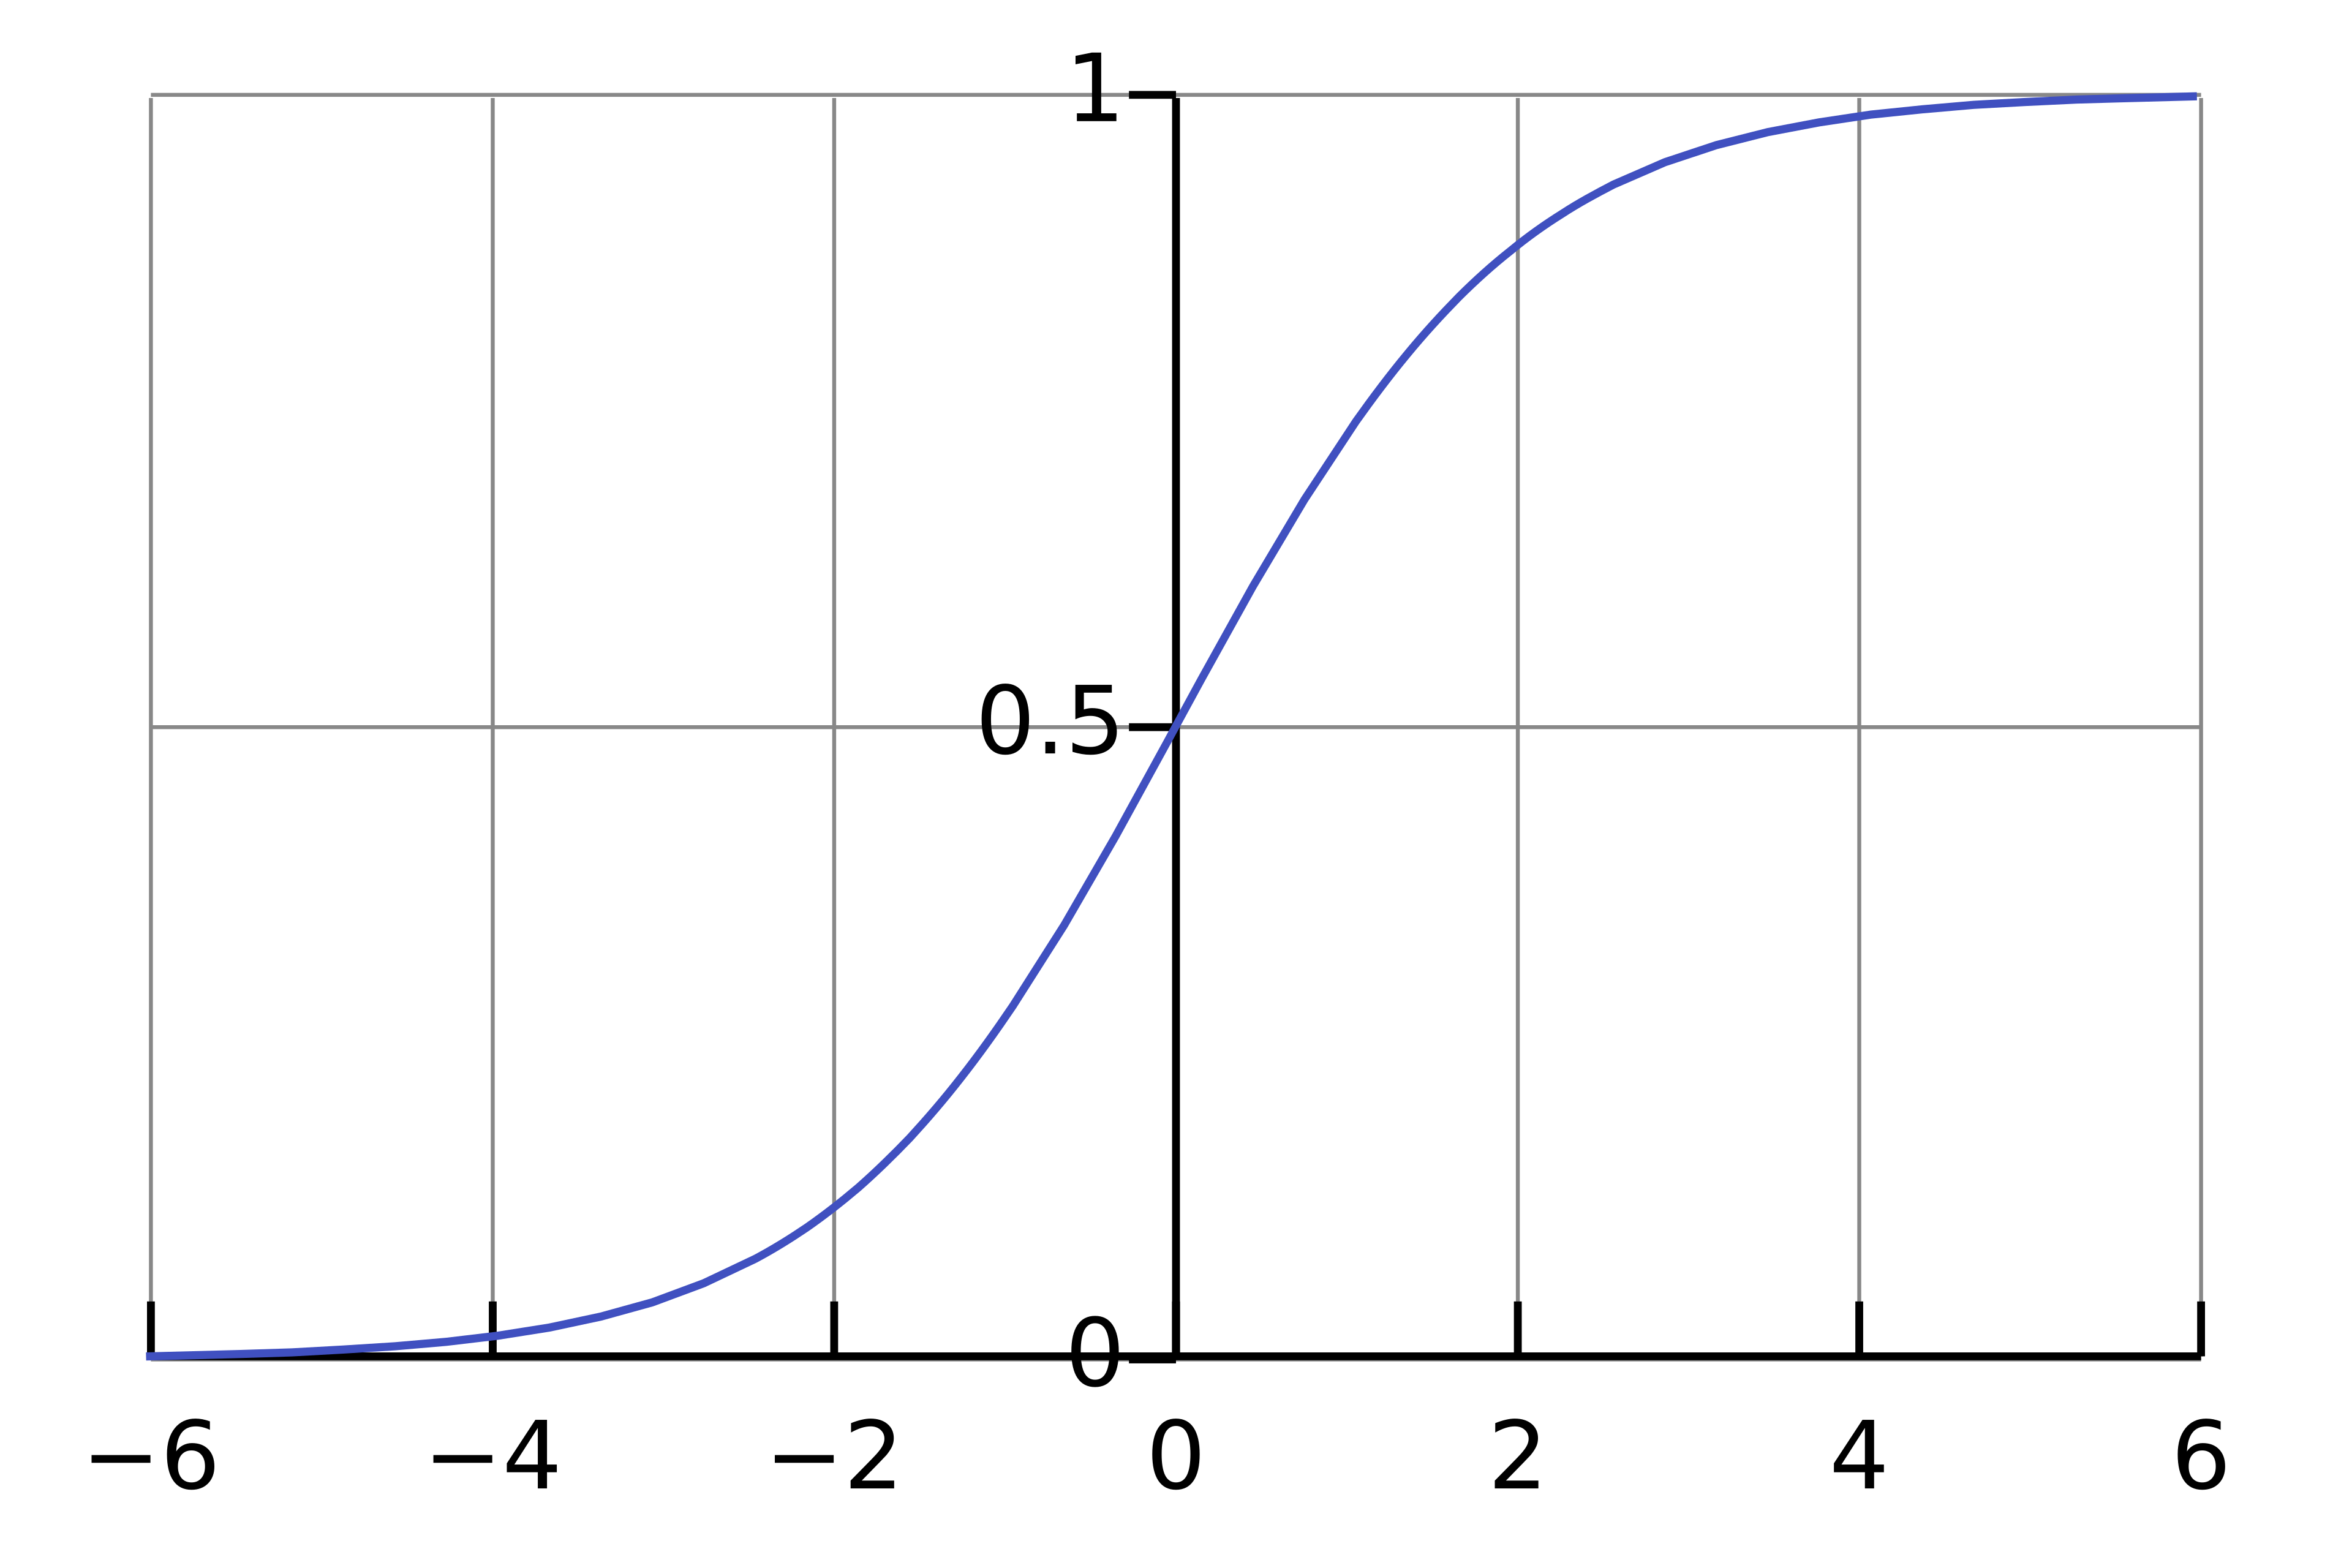

### 모델은 어떻게 학습하는가

학습 데이터의 입력과 정답이 주어지면, 모델은 실제 정답 클래스에 높은 확률을 주도록 가중치 $w$와 절편 $b$를 조정한다. 각 사례의 입력으로 가중합 $z$를 구하고 시그모이드를 적용하면 그 사례가 양성일 확률 $p$를 얻으며, 학습 사례마다 이 계산을 수행한다.

한 사례의 실제 정답을 $y$라고 하면, 정답 클래스에 부여한 확률은 다음과 같다.

- 실제 정답이 양성인 $y=1$이면 정답의 확률은 $p$다.
- 실제 정답이 음성인 $y=0$이면 정답의 확률은 $1-p$다.

정답 클래스에 부여한 확률에 마이너스 로그를 취하면 이진 교차 엔트로피(로그 손실)가 된다. 로지스틱 회귀는 이 손실을 학습에 사용하며, 한 사례의 손실 $\ell(y,p)$는 다음과 같이 계산한다. 식에서 $\log$는 자연로그를 뜻한다.

$$
\ell(y,p)=
\begin{cases}
-\log(p) & y=1 \\
-\log(1-p) & y=0
\end{cases}
$$

식의 조건 $y=1$, $y=0$은 실제 정답 클래스를 나타낸다.
정답 클래스에 부여한 확률이 1에 가까우면 손실은 0에 가까워지고, 0에 가까우면 손실은 매우 커진다. 따라서 손실을 줄이면 정답 클래스에 더 높은 확률을 주도록 학습할 수 있다.

예를 들어 실제 정답이 양성일 때 모델이 예측한 확률이 $p=0.9$이면 손실은 약 0.105, $p=0.1$이면 약 2.303이다.


### 전체 데이터의 손실

$i$번째 사례의 실제 정답을 $y_i$, 양성 클래스의 예측 확률을 $p_i$라고 하면, 그 사례의 손실은 $\ell(y_i,p_i)$다.

각 사례의 손실을 모두 더한 값을 $S$로 나타내면 다음과 같다. 이때 $\sum$은 지정한 범위의 값을 더한다는 기호다.

$$
S=\sum_{i=1}^{N}\ell(y_i,p_i)
=\ell(y_1,p_1)+\ell(y_2,p_2)+\cdots+\ell(y_N,p_N)
$$

이 합을 사례 수 $N$으로 나누면 평균 손실 $L$이 된다.

$$
L=\frac{S}{N}=\frac{1}{N}\sum_{i=1}^{N}\ell(y_i,p_i)
$$

이처럼 사례별 예측 확률 $p_i$로 손실 $\ell(y_i,p_i)$를 계산한 뒤 평균을 내면, 전체 학습 데이터에 대한 손실 $L$을 얻는다.


### 가중치와 절편 조정

가중치와 절편은 연속적인 값을 가지므로 가능한 조합을 모두 시험하기 어렵다. 모델은 현재 값에서 손실이 어느 방향으로 변하는지 계산하고, 손실이 줄어드는 쪽으로 값을 반복해서 조정한다. 이렇게 손실을 줄이는 값을 찾는 과정을 최적화라고 한다.

대표적인 최적화 방법인 경사하강법은 현재 위치에서 손실 곡선의 기울기를 구한 뒤, 그 반대 방향으로 가중치를 조금씩 조정한다. 이때 한 번에 조정하는 크기는 학습률로 정한다.

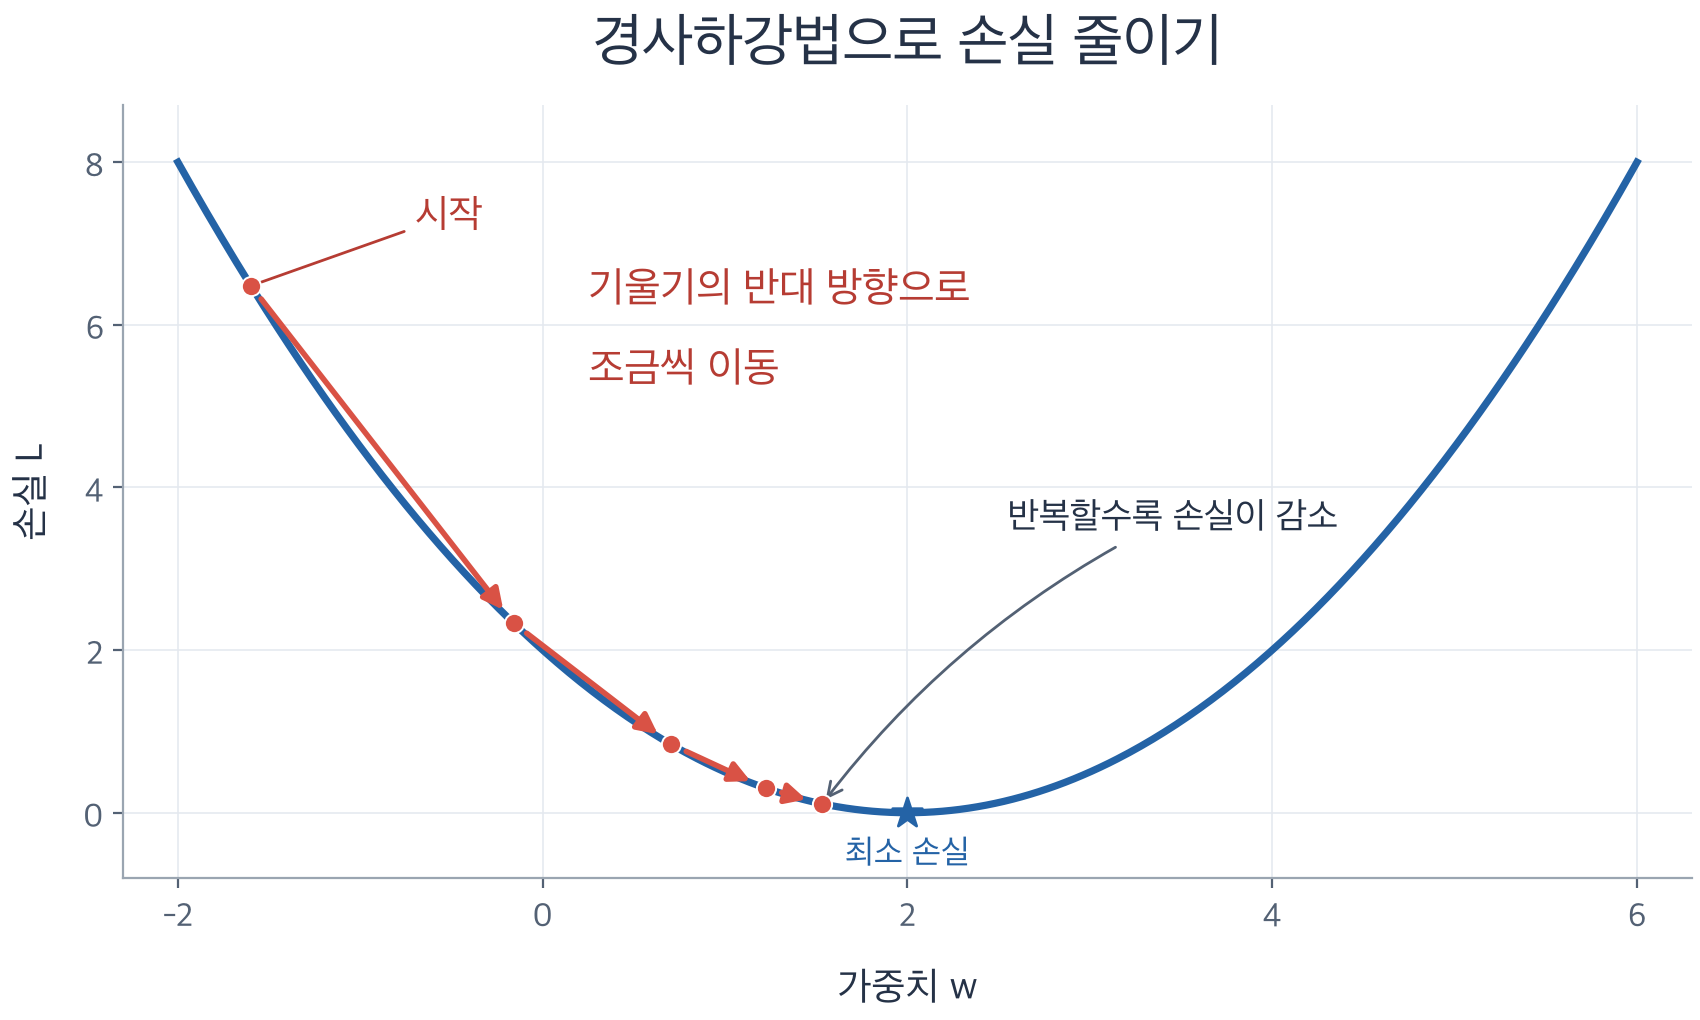

가중치 하나에 따른 손실을 단순화한 그림에서, 왼쪽 출발점은 가중치를 늘리는 쪽으로 이동할수록 손실이 줄어든다. 가중치와 절편이 여러 개일 때도 각각의 변화가 손실에 미치는 영향을 계산해 조정한다.


### 유방암 진단 데이터 불러오기

Wisconsin 유방암 진단 데이터에는 유방 종괴에서 채취한 검체 569개의 기록이 담겨 있다. 한 행이 검체 하나에 해당하며, 검체 이미지에 있는 세포핵의 측정값을 요약한 특성과 악성·양성 종양 여부를 포함한다. 이 특성 중 세포핵의 크기와 질감 등을 이용해 악성 여부를 예측하는 이진 분류 문제다.

입력은 반지름·질감·둘레·면적 등의 측정값을 바탕으로 만든 30개의 수치형 특성이며, 결측값은 없다.

| 역할 | 열 | 의미 |
| --- | --- | --- |
| 입력 | `mean radius` | 세포핵 중심에서 윤곽까지 거리로 구한 반지름의 평균 |
| 입력 | `mean texture` | 세포핵 이미지의 밝기 값 표준편차로 구한 질감의 평균 |
| 정답 | `malignant` | 악성 1, 양성 종양 0 |

관심 대상으로 정한 악성(1)을 분류의 양성 클래스로 사용하며, 종양의 성질을 나타내는 '양성 종양'은 클래스 0으로 구분한다.


In [2]:
cancer = load_breast_cancer(as_frame=True)
X_all = cancer.data.copy()  # 전체 입력: (569, 30)
feature_columns = ["mean radius", "mean texture"]
X = X_all[feature_columns].copy()

# 원본 정답은 악성 0, 양성 종양 1이다. 악성을 1로 바꾸고 정답 열의 이름을 정한다.
y = (cancer.target == 0).astype(int).rename("malignant")

# shape: X는 (행 수, 특성 수), y는 (행 수,)
print("X:", X.shape, "y:", y.shape)
display(pd.concat([X, y], axis=1).head())
display(X.isna().sum().rename("missing_count"))


X: (569, 2) y: (569,)


,mean radius,mean texture,malignant
0,17.99,10.38,1
1,20.57,17.77,1
2,19.69,21.25,1
3,11.42,20.38,1
4,20.29,14.34,1


mean radius     0
mean texture    0
Name: missing_count, dtype: int64

### 학습 데이터 준비

클래스 비율을 비슷하게 유지하며 데이터를 학습 60%, 검증 20%, 테스트 20%로 나누고, 반지름과 질감은 학습 데이터 기준으로 표준화한다.


In [3]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,  
    stratify=y,  # 나뉜 데이터에서도 악성·양성 종양 비율을 유지한다.
    random_state=SEED, 
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED)

split_summary = pd.DataFrame([
    {"split": name, "rows": len(labels), "benign": int((labels == 0).sum()),
     "malignant": int((labels == 1).sum()), "malignant_rate": float(labels.mean())}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
])
display(split_summary)


,split,rows,benign,malignant,malignant_rate
0,train,341,214,127,0.372434
1,validation,114,71,43,0.377193
2,test,114,72,42,0.368421


In [4]:
scaler = StandardScaler()

X_train_processed = scaler.fit_transform(X_train)
X_val_processed = scaler.transform(X_val)

processed_preview = pd.DataFrame(
    X_train_processed, columns=feature_columns, index=X_train.index)
display(processed_preview.head())


,mean radius,mean texture
194,0.193816,0.868298
46,-1.660366,-0.594469
332,-0.818973,0.099025
76,-0.176242,-1.949308
124,-0.220760,-0.697804


### 로지스틱 회귀 학습과 예측

scikit-learn의 로지스틱 회귀 분류 모델 클래스인 `LogisticRegression`을 사용한다. 전처리된 학습 데이터로 모델을 학습한 뒤, 같은 기준으로 전처리한 검증 데이터를 전달해 클래스를 예측한다.

이진 로지스틱 회귀의 `predict()`는 임계값 0.5를 기준으로 클래스를 반환한다. 이 데이터에서는 악성 확률이 0.5를 초과하면 악성(1), 0.5 이하이면 양성 종양(0)으로 분류한다.


In [5]:
logistic_model = LogisticRegression(max_iter=1000)  # max_iter: 학습 반복 횟수 상한

# fit: 전처리된 학습 입력과 정답으로 모델을 학습한다.
logistic_model.fit(X_train_processed, y_train)

# predict: 클래스 번호를 담은 (검증 행 수,) 배열을 반환한다.
validation_prediction = logistic_model.predict(X_val_processed)

validation_results = pd.DataFrame({
    "actual_malignant": y_val,
    "predicted_malignant": validation_prediction,
})
display(validation_results.head())


,actual_malignant,predicted_malignant
488,0,0
212,1,1
175,0,0
482,0,0
361,0,0


## 분류 성능 평가하기

### 혼동 행렬

혼동 행렬(confusion matrix)은 실제 클래스와 예측 클래스를 교차해서 맞힌 경우와 틀린 경우를 센 표다. 
T/F는 예측이 맞았는지(True/False), P/N은 양성·음성(Positive/Negative) 중 무엇으로 예측했는지를 나타낸다.

| 실제 / 예측 | 음성 클래스 0: 양성 종양 | 양성 클래스 1: 악성 |
| --- | --- | --- |
| 음성 클래스 0: 양성 종양 | TN: 양성 종양을 양성 종양으로 예측 | FP: 양성 종양을 악성으로 예측 |
| 양성 클래스 1: 악성 | FN: 악성을 양성 종양으로 예측 | TP: 악성을 악성으로 예측 |

대각선의 TN·TP는 맞힌 경우, 나머지 FP·FN은 틀린 경우에 해당한다. 이 네 값을 함께 읽으면 전체에서 맞힌 건수뿐 아니라 어느 클래스를 잘못 예측했는지도 확인할 수 있다.


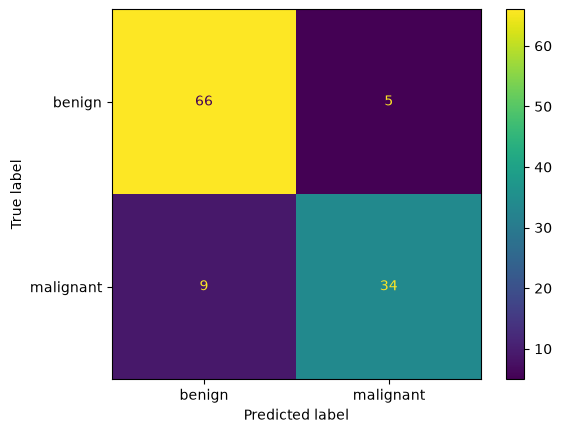

In [6]:
# 실제 클래스는 행, 예측 클래스는 열에 표시한다.
ConfusionMatrixDisplay.from_predictions(
    y_val, validation_prediction, labels=[0, 1], display_labels=["benign", "malignant"])
plt.show()


### 분류 지표

평가 지표는 예측 결과를 서로 다른 기준으로 요약한다. 이 실습에서는 악성(1)을 기준으로 정밀도·재현율·F1을 계산한다.

- 정확도(accuracy): 전체 검증 사례 중 악성과 양성 종양을 올바르게 예측한 비율이며, $\frac{TP+TN}{TP+TN+FP+FN}$로 계산한다.
- 정밀도(precision): 악성으로 예측한 사례 중 실제 악성인 비율로, 악성이라는 예측이 얼마나 정확한지 나타낸다. 계산식은 $\frac{TP}{TP+FP}$다.
- 재현율(recall): 실제 악성 사례 중 모델이 악성으로 찾아낸 비율로, 악성을 얼마나 놓치지 않고 찾았는지 나타낸다. 계산식은 $\frac{TP}{TP+FN}$다.
- F1: 정밀도와 재현율을 함께 요약하는 지표로, 두 값의 조화평균이다. 정밀도를 $P$, 재현율을 $R$이라고 하면 $F1 = \frac{2PR}{P+R}$로 계산하며, 두 값이 모두 높을 때 F1도 높아진다. 조화평균을 쓰는 이유는 정밀도와 재현율 중 낮은 값을 더 크게 반영하기 위해서다.


In [7]:
# 지표 함수에는 정답, 예측 순서로 전달한다. zero_division=0은 분모가 0인 지표를 0으로 표시한다.
validation_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_val, validation_prediction),
    "precision": precision_score(y_val, validation_prediction, zero_division=0),
    "recall": recall_score(y_val, validation_prediction, zero_division=0),
    "f1": f1_score(y_val, validation_prediction, zero_division=0),
}])
display(validation_metrics)


,accuracy,precision,recall,f1
0,0.877193,0.871795,0.790698,0.829268


### 클래스 비율과 정확도

정확도는 전체 사례 중 맞힌 비율이므로, 사례 수가 많은 클래스의 예측 결과가 점수에 더 크게 반영된다.

가상의 검체 100개 중 양성 종양이 95개, 악성이 5개라고 하자. 모든 검체를 양성 종양으로 예측하면 95개를 맞혀 정확도는 95%가 되지만, 악성 5개는 모두 놓쳐 악성 재현율은 0%가 된다. 높은 정확도가 사례 대부분을 차지하는 양성 종양의 예측 결과에서 나온 예다.

악성을 얼마나 찾아냈는지는 재현율로, 악성이라는 예측이 얼마나 정확했는지는 정밀도로 확인한다. 혼동 행렬에서는 악성을 놓친 건수(FN)와 양성 종양을 악성으로 잘못 예측한 건수(FP)를 구분해 확인한다.


## 임계값 조정

### 예측 확률과 임계값

임계값은 어떤 오류를 줄일지에 따라 조정할 수 있다. 같은 악성 확률 0.4라도 임계값이 0.5이면 양성 종양(0), 0.3이면 악성(1)으로 예측한다.

`predict_proba()`는 각 클래스에 속할 확률을 반환한다. 클래스 1에 해당하는 악성 확률을 가져와 원하는 임계값과 비교하면 새로운 예측 클래스를 얻는다.

악성 예측 확률이 0.4~0.6인 검체의 실제 정답과 임계값별 분류 결과를 비교한다. 음성(0)은 양성 종양, 양성(1)은 악성을 뜻한다.


In [9]:
# classes_: 학습 정답 y_train에서 확인한 클래스 순서이며, predict_proba의 열 순서와 같다.
# index(1): 악성을 나타내는 클래스 1의 열 위치를 찾는다.
positive_column = list(logistic_model.classes_).index(1)

# predict_proba: 각 검체의 클래스별 확률을 (검증 행 수, 클래스 수) 배열로 반환한다.
# [:, positive_column]: 모든 검체의 행을 유지하고 악성 확률 열을 선택한다.
validation_scores = logistic_model.predict_proba(X_val_processed)[:, positive_column]

threshold_results = pd.DataFrame({
    "actual_malignant": y_val,
    "malignant_probability": validation_scores,
})
for threshold in [0.3, 0.5, 0.7]:
    predicted_class = (threshold_results["malignant_probability"] > threshold).astype(int)
    threshold_results[f"threshold_{threshold:.1f}"] = predicted_class

# between: 양 끝값을 포함해 0.4~0.6 범위에 속하는지 확인한다.
near_threshold_results = threshold_results.loc[
    threshold_results["malignant_probability"].between(0.4, 0.6)
].sort_values("malignant_probability")
display(near_threshold_results)


,actual_malignant,malignant_probability,threshold_0.3,threshold_0.5,threshold_0.7
457,0,0.418751,1,0,0
243,0,0.458512,1,0,0
257,1,0.461300,1,0,0
16,1,0.471084,1,0,0
291,0,0.478309,1,0,0
495,0,0.516601,1,1,0
26,1,0.522302,1,1,0
552,0,0.540196,1,1,0
57,1,0.553554,1,1,0
543,0,0.564277,1,1,0


### 임계값별 혼동행렬 비교

같은 검증 데이터의 악성 예측 확률에 임계값 0.3·0.5·0.7을 각각 적용한다. 임계값을 낮출 때 놓친 악성(FN)과 양성 종양을 악성으로 잘못 판단한 사례(FP)가 어떻게 달라지는지 비교한다. 악성을 놓치는 일을 줄이는 것이 목적이라면 어느 임계값이 적합한지 정밀도·재현율과 함께 살펴본다.


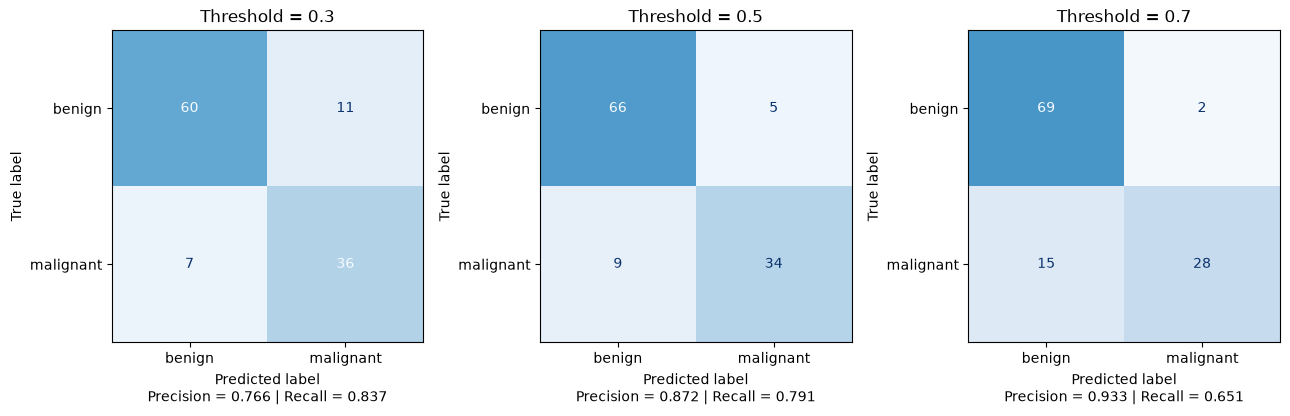

In [10]:
thresholds = [0.3, 0.5, 0.7]
# subplots: 가로로 세 개의 그래프를 배치하고 Figure와 Axes 배열을 반환한다.
fig, axes = plt.subplots(1, len(thresholds), figsize=(13, 4.5))

for ax, threshold in zip(axes, thresholds):
    threshold_prediction = (validation_scores > threshold).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val, threshold_prediction,
        labels=[0, 1], display_labels=["benign", "malignant"],
        ax=ax, colorbar=False, cmap="Blues", im_kw={"vmin": 0, "vmax": len(y_val)})
    threshold_precision = precision_score(y_val, threshold_prediction, zero_division=0)
    threshold_recall = recall_score(y_val, threshold_prediction, zero_division=0)
    ax.set_title(f"Threshold = {threshold:.1f}")
    ax.set_xlabel(
        f"Predicted label\nPrecision = {threshold_precision:.3f} | Recall = {threshold_recall:.3f}")

plt.tight_layout()
plt.show()


### 임계값에 따른 변화 해석

같은 예측 확률에서 임계값을 낮추면 악성으로 예측하는 사례가 유지되거나 늘어난다. 따라서 TP·FP는 유지되거나 늘어나고, FN은 유지되거나 줄어든다.
재현율은 유지되거나 높아지며, 정밀도는 새로 악성으로 예측한 사례의 실제 정답에 따라 오르거나 내릴 수 있다.

임계값은 예측 목적에 맞게 선택한다. 악성을 놓치는 일을 줄이려면 임계값을 낮추는 쪽을, 양성 종양을 악성으로 잘못 판단하는 일을 줄이려면 높이는 쪽을 검토한다. 검증 데이터에서 여러 임계값의 정밀도·재현율과 오탐·미탐 건수를 비교하고, 줄이려는 오류와 허용할 수 있는 오류 수준에 맞춰 임계값을 정한다.



## 규제와 입력 특성 비교

### 규제 강도 바꾸기

로지스틱 회귀의 기본 설정인 L2 규제는 가중치의 제곱합에 벌점을 주며, 하이퍼파라미터 `C`로 그 강도를 조절한다. `C`는 규제 강도의 역수이므로 값을 작게 지정할수록 규제가 강해진다.

같은 학습·검증 데이터로 `C=0.5`와 `C=0.1`인 모델을 학습하고, 기본 설정인 `C=1.0` 모델과 학습·검증 F1을 비교한다. 각 모델에서 기준 모델과 예측 클래스가 달라진 사례 수도 확인한다.
F1은 예측 클래스로 계산하므로, 예측 확률이 달라져도 임계값 0.5에서 클래스가 그대로라면 F1도 같다. 예측이 바뀐 사례 수와 F1의 변화를 함께 해석한다.

학습 F1에 비해 검증 F1이 낮으면 과적합 가능성을 살펴보되, 이 데이터와 C 범위에서는 점수 차이가 작을 수 있다는 점도 함께 고려한다. 규제를 강화했을 때 두 점수와 예측이 어떻게 달라졌는지 관찰한 결과로 설명한다.


In [11]:
# C: 규제 강도의 역수로, 작을수록 규제가 강하고 클수록 약하다.
practice_model = LogisticRegression(C=0.5, max_iter=1000)
practice_model.fit(X_train_processed, y_train)
practice_prediction = practice_model.predict(X_val_processed)

stronger_model = LogisticRegression(C=0.1, max_iter=1000)
stronger_model.fit(X_train_processed, y_train)
stronger_prediction = stronger_model.predict(X_val_processed)

regularization_comparison = pd.DataFrame([
    {"C": c_value,
     "train_f1": f1_score(y_train, model.predict(X_train_processed), zero_division=0),
     "val_f1": f1_score(y_val, prediction, zero_division=0),
     # 기준 모델(C=1.0)과 예측 클래스가 다른 검증 사례 수
     "changed_predictions": int((prediction != validation_prediction).sum())}
    for c_value, model, prediction in [
        (1.0, logistic_model, validation_prediction),
        (0.5, practice_model, practice_prediction),
        (0.1, stronger_model, stronger_prediction),
    ]
])
display(regularization_comparison)


,C,train_f1,val_f1,changed_predictions
0,1.0,0.855967,0.829268,0
1,0.5,0.853556,0.829268,0
2,0.1,0.842553,0.810127,3


### 전체 특성으로 확장하기

두 특성에 담긴 크기와 질감 정보에 세포핵의 윤곽·대칭성 등 나머지 특성을 더하면, 모델은 총 30개 특성의 가중합으로 악성 확률을 추정한다.

입력 특성 수에 따른 차이를 비교하기 위해 학습·검증 사례와 임계값 0.5, 기본 모델의 `C=1.0`은 유지하고 입력만 두 특성에서 전체 30개 특성으로 바꾸어 학습한다. 전체 특성에서는 `C=0.5` 모델도 학습해 규제 강도에 따른 차이를 비교한다.


In [12]:
# loc: 기존 분할의 행 인덱스로 같은 사례의 전체 특성을 선택한다.
X_train_all = X_all.loc[X_train.index]
X_val_all = X_all.loc[X_val.index]
all_scaler = StandardScaler()
X_train_all_processed = all_scaler.fit_transform(X_train_all)  # 모양: (학습 행 수, 30)
X_val_all_processed = all_scaler.transform(X_val_all)  # 모양: (검증 행 수, 30)

all_feature_model = LogisticRegression(C=1.0, max_iter=1000)
all_feature_model.fit(X_train_all_processed, y_train)
all_feature_prediction = all_feature_model.predict(X_val_all_processed)

all_feature_regularized_model = LogisticRegression(C=0.5, max_iter=1000)
all_feature_regularized_model.fit(X_train_all_processed, y_train)
all_feature_regularized_prediction = all_feature_regularized_model.predict(X_val_all_processed)

model_comparison = pd.DataFrame([
    {"model": name,
     "val_accuracy": accuracy_score(y_val, prediction),
     "val_precision": precision_score(y_val, prediction, zero_division=0),
     "val_recall": recall_score(y_val, prediction, zero_division=0),
     "val_f1": f1_score(y_val, prediction, zero_division=0),
     "missed_malignant": int(((y_val == 1) & (prediction == 0)).sum())}
    for name, prediction in [
        ("2 features, C=1.0", validation_prediction),
        ("2 features, C=0.5", practice_prediction),
        ("2 features, C=0.1", stronger_prediction),
        ("30 features, C=1.0", all_feature_prediction),
        ("30 features, C=0.5", all_feature_regularized_prediction),
    ]
])
display(model_comparison)


,model,val_accuracy,val_precision,val_recall,val_f1,missed_malignant
0,"2 features, C=1.0",0.877193,0.871795,0.790698,0.829268,9
1,"2 features, C=0.5",0.877193,0.871795,0.790698,0.829268,9
2,"2 features, C=0.1",0.868421,0.888889,0.744186,0.810127,11
3,"30 features, C=1.0",0.973684,0.954545,0.976744,0.965517,1
4,"30 features, C=0.5",0.973684,0.954545,0.976744,0.965517,1


### 최종 테스트

비교한 다섯 모델 중 검증 F1이 가장 높은 모델을 선택하되, 동점이면 비교 표에 먼저 나온 모델을 사용한다. 선택한 모델에 맞는 입력 특성과 학습된 표준화 기준으로 테스트 데이터를 변환한 뒤 최종 평가한다.

최종 평가에는 이미 학습된 모델을 사용하며, 테스트 결과로 모델을 다시 고르지 않는다.


In [13]:
# idxmax: 최댓값인 행의 인덱스를 반환한다. 동점이면 먼저 나온 행을 선택한다.
selected_index = model_comparison["val_f1"].idxmax()
selected_name = model_comparison.loc[selected_index, "model"]
# 각 후보의 입력 열, 학습된 표준화 객체, 학습된 모델을 함께 선택한다.
candidates = {
    "2 features, C=1.0": (feature_columns, scaler, logistic_model),
    "2 features, C=0.5": (feature_columns, scaler, practice_model),
    "2 features, C=0.1": (feature_columns, scaler, stronger_model),
    "30 features, C=1.0": (X_all.columns, all_scaler, all_feature_model),
    "30 features, C=0.5": (X_all.columns, all_scaler, all_feature_regularized_model),
}
selected_columns, final_scaler, final_model = candidates[selected_name]
print("선택한 모델:", selected_name)

final_test_input = X_all.loc[X_test.index, selected_columns]
X_test_processed = final_scaler.transform(final_test_input)
test_prediction = final_model.predict(X_test_processed)
print("테스트 정확도:", accuracy_score(y_test, test_prediction))
print("테스트 정밀도:", precision_score(y_test, test_prediction, zero_division=0))
print("테스트 재현율:", recall_score(y_test, test_prediction, zero_division=0))
print("테스트 F1:", f1_score(y_test, test_prediction, zero_division=0))


선택한 모델: 30 features, C=1.0
테스트 정확도: 0.9736842105263158
테스트 정밀도: 0.975609756097561
테스트 재현율: 0.9523809523809523
테스트 F1: 0.963855421686747


## 연습문제: 타이타닉 생존 여부 예측

### 승객 데이터 불러오기

Titanic은 승객 891명의 탑승 정보와 생존 여부를 담고 있으며, 한 행은 승객 한 명이다. 나이·탑승 요금·동반 가족 수·객실 등급·성별·출항지로 생존 여부를 예측하는 이진 분류 문제다. 생존(1)을 양성 클래스로 사용한다.

| 역할 | 열 | 의미 |
| --- | --- | --- |
| 숫자 입력 | `age` | 나이, 년 |
| 숫자 입력 | `fare` | 탑승 요금 |
| 숫자 입력 | `sibsp`, `parch` | 함께 탑승한 형제자매·배우자 수, 부모·자녀 수 |
| 범주 입력 | `pclass` | 객실 등급: 1·2·3 |
| 범주 입력 | `sex`, `embarked` | 성별, 출항지 코드 |
| 정답 | `survived` | 생존 1, 사망 0 |


In [ ]:
import seaborn as sns

# load_dataset: 온라인 예제 데이터를 DataFrame으로 불러온다.
exercise_titanic = sns.load_dataset("titanic")
exercise_numeric_columns = ["age", "fare", "sibsp", "parch"]
exercise_category_columns = ["pclass", "sex", "embarked"]
exercise_X = exercise_titanic[exercise_numeric_columns + exercise_category_columns].copy()
exercise_y = exercise_titanic["survived"].copy()


### 직접 작성하기: 로지스틱 회귀로 생존 여부 예측

타이타닉 데이터를 전처리하고 로지스틱 회귀 모델을 학습해 생존 여부를 예측해 보세요. 검증 데이터에서 분류 성능과 임계값에 따른 변화를 비교하고, 선택한 설정으로 테스트 데이터를 평가해 보세요.
